# Cannabis consumption: exploration and preparation

Phase 1 covers understanding, cleaning, exploration, and a reproducible train/test split. No predictive model is trained.

| Target | Meaning | Original cannabis codes |
|---|---|---|
| 0 | Never used | CL0 |
| 1 | Former user: last used more than one year ago | CL1, CL2 |
| 2 | Recent user: used within the last year | CL3, CL4, CL5, CL6 |

Source: [UCI Drug Consumption (Quantified)](https://archive.ics.uci.edu/dataset/373/drug+consumption+quantified), Fehrman, Egan & Mirkes (2015), [DOI](https://doi.org/10.24432/C5TC7S), CC BY 4.0.

The course brief supplies background; this notebook implements your requested preparation stage. Read and understand each decision before using it in your submission.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
import hashlib
import json
import platform
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Support launching from the project root or the notebooks folder.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW = ROOT / "data/raw/drug_consumption.data"
OUT = ROOT / "data/processed"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
for folder in (RAW.parent, OUT, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)
SEED = 42
TEST_SIZE = 0.20
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load the original file

The source file has **no header**. Provide all 32 names in the documented order so that the first person is not mistaken for a header. Preserve the raw file. Download only when absent, and verify the checksum of the source used for this project.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/373/drug%2Bconsumption%2Bquantified.zip"
EXPECTED_SHA256 = "90b8cf500b07ad455baf9fe1dc519998c75a1df6d87f6bd7069176f0826ea8c1"
if not RAW.exists():
    with urlopen(URL, timeout=60) as response:
        archive = ZipFile(BytesIO(response.read()))
    RAW.write_bytes(archive.read("drug_consumption.data"))
raw_hash = hashlib.sha256(RAW.read_bytes()).hexdigest()
assert raw_hash == EXPECTED_SHA256, "Source changed; review it before proceeding."

FEATURES = ["age", "gender", "education", "country", "ethnicity", "nscore", "escore",
            "oscore", "ascore", "cscore", "impulsive", "ss"]
DRUGS = ["alcohol", "amphet", "amyl", "benzos", "caff", "cannabis", "choc", "coke",
         "crack", "ecstasy", "heroin", "ketamine", "legalh", "lsd", "meth",
         "mushrooms", "nicotine", "semer", "vsa"]
raw = pd.read_csv(RAW, header=None, names=["id"] + FEATURES + DRUGS)
assert raw.shape == (1885, 32)
print(f"Raw data: {len(raw):,} respondents, {raw.shape[1]} columns")
display(raw.head())

Raw data: 1,885 respondents, 32 columns


,id,age,gender,education,country,ethnicity,nscore,escore,oscore,ascore,...,ecstasy,heroin,ketamine,legalh,lsd,meth,mushrooms,nicotine,semer,vsa
0,1,0.49788,0.48246,-0.05921,0.96082,0.12600,0.31287,-0.57545,-0.58331,-0.91699,...,CL0,CL0,CL0,CL0,CL0,CL0,CL0,CL2,CL0,CL0
1,2,-0.07854,-0.48246,1.98437,0.96082,-0.31685,-0.67825,1.93886,1.43533,0.76096,...,CL4,CL0,CL2,CL0,CL2,CL3,CL0,CL4,CL0,CL0
2,3,0.49788,-0.48246,-0.05921,0.96082,-0.31685,-0.46725,0.80523,-0.84732,-1.62090,...,CL0,CL0,CL0,CL0,CL0,CL0,CL1,CL0,CL0,CL0
3,4,-0.95197,0.48246,1.16365,0.96082,-0.31685,-0.14882,-0.80615,-0.01928,0.59042,...,CL0,CL0,CL2,CL0,CL0,CL0,CL0,CL2,CL0,CL0
4,5,0.49788,0.48246,1.98437,0.96082,-0.31685,0.73545,-1.63340,-0.45174,-0.30172,...,CL1,CL0,CL0,CL1,CL0,CL0,CL2,CL2,CL0,CL0


## 2. Understand the variables

The 12 predictors are demographic attributes and personality/behavioral scores. The ID is a reference only. There are 18 real-substance responses plus `semer`, the fictitious substance Semeron used as a response-quality check. Only the 12 predictors enter X; other drug answers are excluded from this prediction task.

| Predictors | Interpretation |
|---|---|
| age, education | Quantified age bands and education levels, not literal years |
| gender, country, ethnicity | Quantified demographic categories |
| nscore, escore, oscore | Neuroticism, extraversion, openness |
| ascore, cscore | Agreeableness, conscientiousness |
| impulsive, ss | Impulsivity and sensation seeking |

Consumption codes are recency categories: CL0 = never, CL1 = over a decade ago, CL2 = last decade, CL3 = last year, CL4 = last month, CL5 = last week, CL6 = last day. They do not measure dosage or dependence. `meth` means **methadone**, not methamphetamine.

Negative predictor scores are valid. UCI already quantified these attributes before release. The fixed lookup tables below decode the demographic values.

In [3]:
MAPS = {
    "age": {-0.95197: "18-24", -0.07854: "25-34", 0.49788: "35-44",
            1.09449: "45-54", 1.82213: "55-64", 2.59171: "65+"},
    "gender": {0.48246: "Female", -0.48246: "Male"},
    "education": {-2.43591: "Left before 16", -1.73790: "Left at 16", -1.43719: "Left at 17",
                  -1.22751: "Left at 18", -0.61113: "Some college, no degree",
                  -0.05921: "Professional certificate/diploma", 0.45468: "University degree",
                  1.16365: "Masters degree", 1.98437: "Doctorate"},
    "country": {-0.09765: "Australia", 0.24923: "Canada", -0.46841: "New Zealand",
                -0.28519: "Other", 0.21128: "Republic of Ireland", 0.96082: "UK", -0.57009: "USA"},
    "ethnicity": {-0.50212: "Asian", -1.10702: "Black", 1.90725: "Mixed-Black/Asian",
                  0.12600: "Mixed-White/Asian", -0.22166: "Mixed-White/Black",
                  0.11440: "Other", -0.31685: "White"},
}
RECENCY = {"CL0": "Never", "CL1": "Over a decade ago", "CL2": "Last decade",
           "CL3": "Last year", "CL4": "Last month", "CL5": "Last week", "CL6": "Last day"}
TARGET_MAP = {"CL0": 0, "CL1": 1, "CL2": 1, "CL3": 2, "CL4": 2, "CL5": 2, "CL6": 2}
CLASS_NAMES = {0: "Never used", 1: "Former user", 2: "Recent user"}
TARGET = "cannabis_class"

# Export a small dictionary for teammates.
descriptions = ["Reference ID", "Quantified age band", "Gender", "Quantified education",
                "Country of residence", "Ethnicity", "Neuroticism", "Extraversion",
                "Openness", "Agreeableness", "Conscientiousness", "Impulsivity", "Sensation seeking"]
dictionary = pd.DataFrame({"column": list(raw.columns) + [TARGET],
    "role": ["reference"] + ["predictor"] * 12 + ["response; excluded from X"] * 19 + ["target"],
    "meaning": descriptions + [f"{d} recency CL0-CL6" for d in DRUGS] + ["0=never, 1=former, 2=recent"]})
dictionary.loc[dictionary.column == "meth", "meaning"] = "Methadone recency"
dictionary.loc[dictionary.column == "semer", "meaning"] = "Fictitious Semeron quality check"
dictionary.to_csv(REPORTS / "data_dictionary.csv", index=False)
display(dictionary)

,column,role,meaning
0,id,reference,Reference ID
1,age,predictor,Quantified age band
2,gender,predictor,Gender
3,education,predictor,Quantified education
4,country,predictor,Country of residence
5,ethnicity,predictor,Ethnicity
6,nscore,predictor,Neuroticism
7,escore,predictor,Extraversion
8,oscore,predictor,Openness
9,ascore,predictor,Agreeableness


## 3. Audit and clean with fixed rules

Inspect record integrity before splitting; do not choose features or transformations based on holdout patterns.

- Fail on missing, nonfinite, unknown demographic/consumption codes, or duplicate IDs instead of guessing corrections.
- Exclude any reported Semeron use (`semer != CL0`). This is our documented cleaning choice: the source includes this fictitious drug to detect over-claiming. It does not prove every other answer in those rows is false.
- Remove exact duplicate responses, ignoring IDs. Keep legitimate extreme scores; extremeness alone is not an error.

No missing-value imputation is required for this file. If missing data appears later, fit any imputer on training data only.

In [4]:
assert raw.isna().sum().sum() == 0, "Missing values require review."
assert raw.id.is_unique and pd.api.types.is_integer_dtype(raw.id)
assert np.isfinite(raw[["id"] + FEATURES].to_numpy(dtype=float)).all()
assert raw[DRUGS].isin(list(RECENCY)).all().all()
for column, mapping in MAPS.items():
    assert raw[column].round(5).isin(mapping).all(), f"Unknown code in {column}"

flagged = raw.semer.ne("CL0")
excluded = raw.loc[flagged, ["id", "semer"]].copy()
excluded["reason"] = "Reported fictitious Semeron use"
excluded.to_csv(REPORTS / "excluded_respondents.csv", index=False)
clean = raw.loc[~flagged].copy()
duplicates = clean.duplicated(subset=FEATURES + DRUGS)
duplicate_ids = clean.loc[duplicates, "id"].tolist()
clean = clean.loc[~duplicates].copy()
clean[TARGET] = clean.cannabis.map(TARGET_MAP).astype("int64")
quality = {"raw_rows": len(raw), "raw_columns": raw.shape[1], "missing_cells": int(raw.isna().sum().sum()),
           "duplicate_responses_raw": int(raw.duplicated(subset=FEATURES + DRUGS).sum()),
           "semeron_excluded": int(flagged.sum()), "duplicate_ids_removed": duplicate_ids,
           "clean_rows": len(clean)}
display(pd.Series(quality, name="value").to_frame())
clean.to_csv(OUT / "cleaned_data.csv", index=False)

,value
raw_rows,1885
raw_columns,32
missing_cells,0
duplicate_responses_raw,0
semeron_excluded,8
duplicate_ids_removed,[]
clean_rows,1877


## 4. Reserve a stratified test set

Use **80% training / 20% test**, seed **42**, stratified by the agreed target. This approximately preserves class proportions. Keep IDs as indices for alignment, never as predictors.

Split before detailed EDA and before fitting preprocessing. Explore training data only below. For Phase 2 tuning, cross-validate within training data and refit preprocessing inside each fold.

In [5]:
indexed = clean.set_index("id", verify_integrity=True)
X, y = indexed[FEATURES].copy(), indexed[TARGET].copy()
# Identical predictor profiles could leak across splits. None occur in this source.
# If this assertion fails on new data, review a grouped splitting strategy.
assert not X.duplicated().any(), "Repeated profiles: review grouped splitting."
X_train_q, X_test_q, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
train = indexed.loc[X_train_q.index].copy()
print(f"Training: {len(y_train):,}; test: {len(y_test):,}")
membership = pd.DataFrame({"id": indexed.index})
membership["split"] = np.where(membership.id.isin(y_train.index), "train", "test")
membership.to_csv(OUT / "split_membership.csv", index=False)

Training: 1,501; test: 376


C:\Users\besta\AppData\Local\Temp\ipykernel_41308\2427967386.py:1: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  indexed = clean.set_index("id", verify_integrity=True)


## 5. Explore training data

Review the class balance, demographics, score distributions, and predictor correlations. These describe an observational, self-reported survey sample, not population prevalence or causal effects. All charts below are saved in `reports/figures/`.

,class,count,percent
0,Never used,330,21.99
1,Former user,378,25.18
2,Recent user,793,52.83


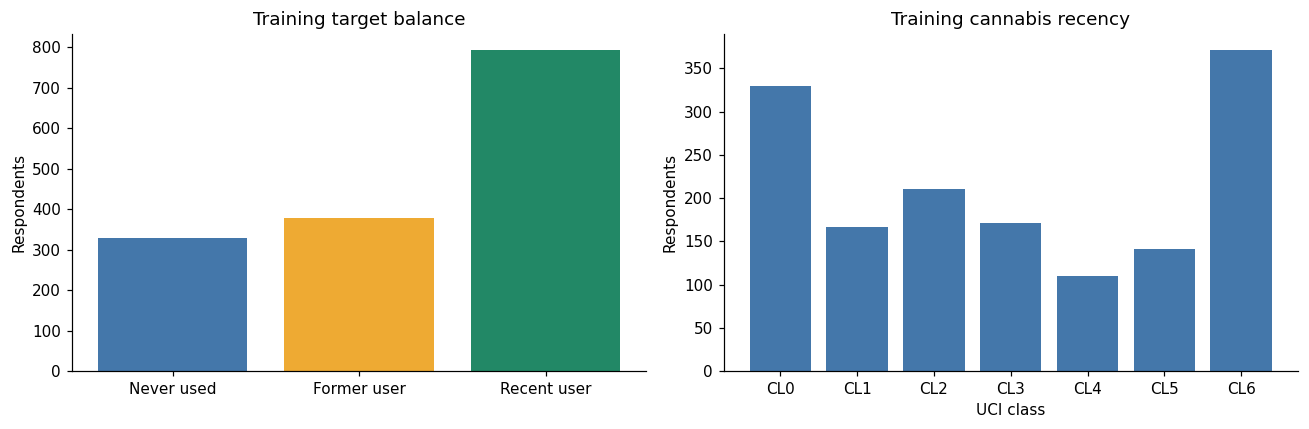

Largest/smallest training class ratio: 2.40
Later use macro-F1, per-class recall, and a confusion matrix alongside accuracy.


In [6]:
counts = y_train.value_counts().reindex(CLASS_NAMES, fill_value=0).sort_index()
balance = pd.DataFrame({"class": pd.Series(CLASS_NAMES), "count": counts,
                        "percent": (100 * counts / len(y_train)).round(2)})
display(balance)
balance.to_csv(REPORTS / "training_class_balance.csv", index_label="target")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(balance["class"], balance["count"], color=["#4477aa", "#eeaa33", "#228866"])
axes[0].set(title="Training target balance", ylabel="Respondents")
recency = train.cannabis.value_counts().reindex(RECENCY, fill_value=0)
axes[1].bar(recency.index, recency.values, color="#4477aa")
axes[1].set(title="Training cannabis recency", ylabel="Respondents", xlabel="UCI class")
fig.tight_layout()
fig.savefig(FIGURES / "training_class_balance.png", bbox_inches="tight")
plt.show()
print(f"Largest/smallest training class ratio: {counts.max()/counts.min():.2f}")
print("Later use macro-F1, per-class recall, and a confusion matrix alongside accuracy.")

,feature,category,count,percent
0,age,18-24,503,33.51
1,age,25-34,398,26.52
2,age,35-44,280,18.65
3,age,45-54,230,15.32
4,age,55-64,75,5.00
5,age,65+,15,1.00
6,gender,Male,758,50.50
7,gender,Female,743,49.50
8,education,"Some college, no degree",405,26.98
9,education,University degree,371,24.72


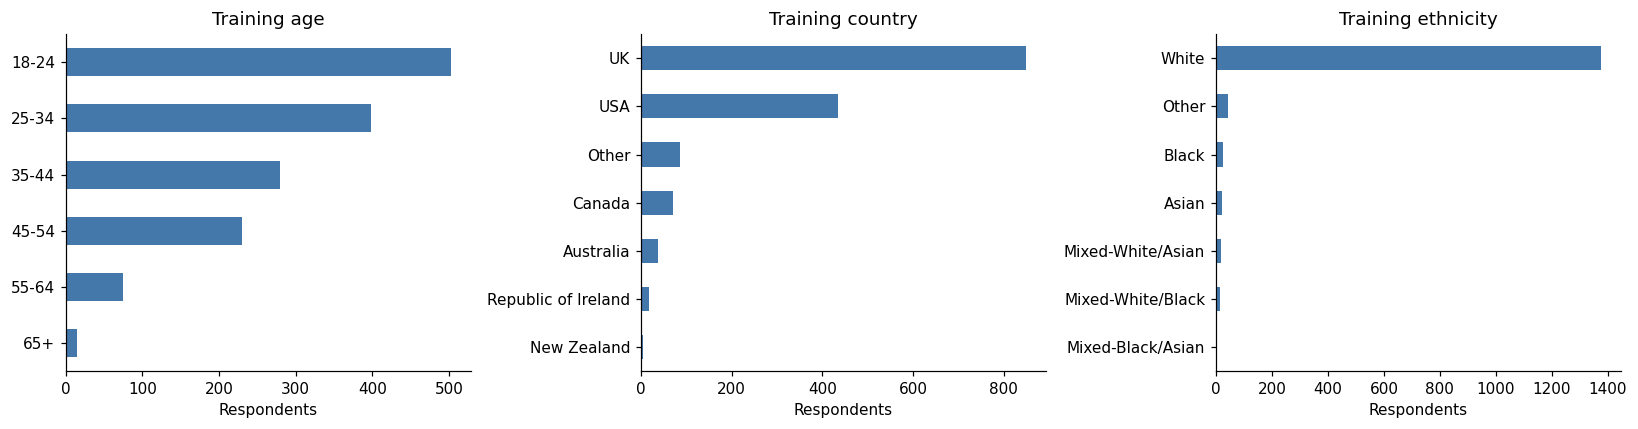

In [7]:
tables = []
for column, mapping in MAPS.items():
    freq = train[column].round(5).map(mapping).value_counts()
    tables.append(pd.DataFrame({"feature": column, "category": freq.index, "count": freq.values,
                               "percent": 100 * freq.values / len(train)}))
demographics = pd.concat(tables, ignore_index=True)
demographics.to_csv(REPORTS / "training_demographics.csv", index=False)
display(demographics.round(2))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["age", "country", "ethnicity"]):
    train[column].round(5).map(MAPS[column]).value_counts().sort_values().plot.barh(ax=ax, color="#4477aa")
    ax.set(title=f"Training {column}", xlabel="Respondents", ylabel="")
fig.tight_layout()
fig.savefig(FIGURES / "training_demographics.png", bbox_inches="tight")
plt.show()

,count,mean,std,min,25%,50%,75%,max
age,1501.0,0.038,0.876,-0.952,-0.952,-0.079,0.498,2.592
gender,1501.0,-0.005,0.483,-0.482,-0.482,-0.482,0.482,0.482
education,1501.0,0.003,0.960,-2.436,-0.611,-0.059,0.455,1.984
country,1501.0,0.373,0.698,-0.570,-0.570,0.961,0.961,0.961
ethnicity,1501.0,-0.312,0.160,-1.107,-0.317,-0.317,-0.317,1.907
nscore,1501.0,-0.004,0.989,-3.464,-0.678,0.043,0.630,3.274
escore,1501.0,-0.013,1.005,-3.274,-0.695,0.003,0.638,3.274
oscore,1501.0,-0.012,0.997,-3.274,-0.717,-0.019,0.723,2.902
ascore,1501.0,-0.003,1.004,-3.464,-0.606,-0.017,0.590,3.157
cscore,1501.0,-0.017,1.012,-3.464,-0.653,-0.007,0.758,3.464


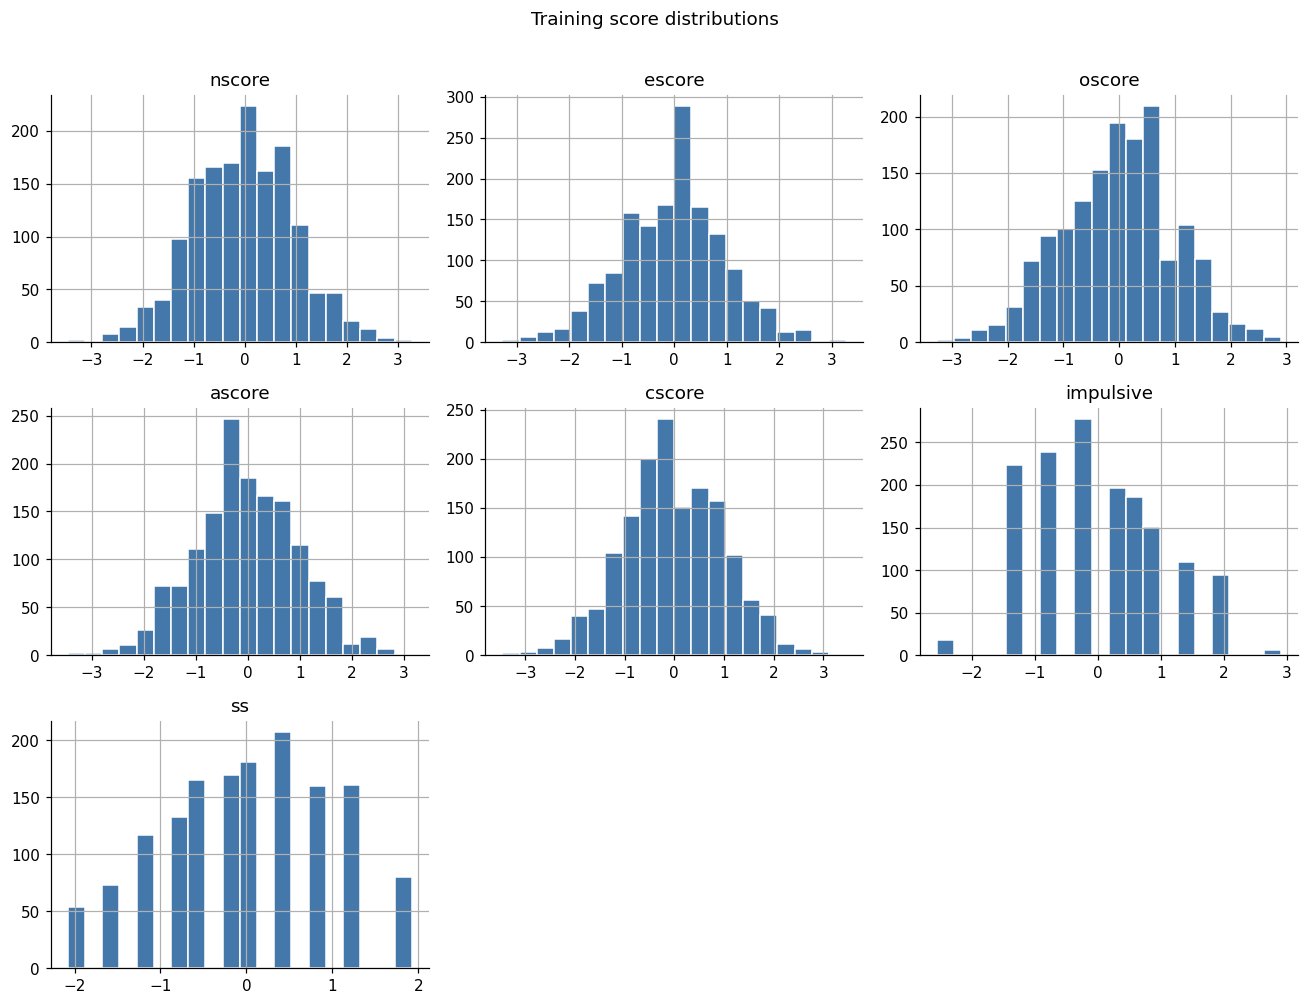

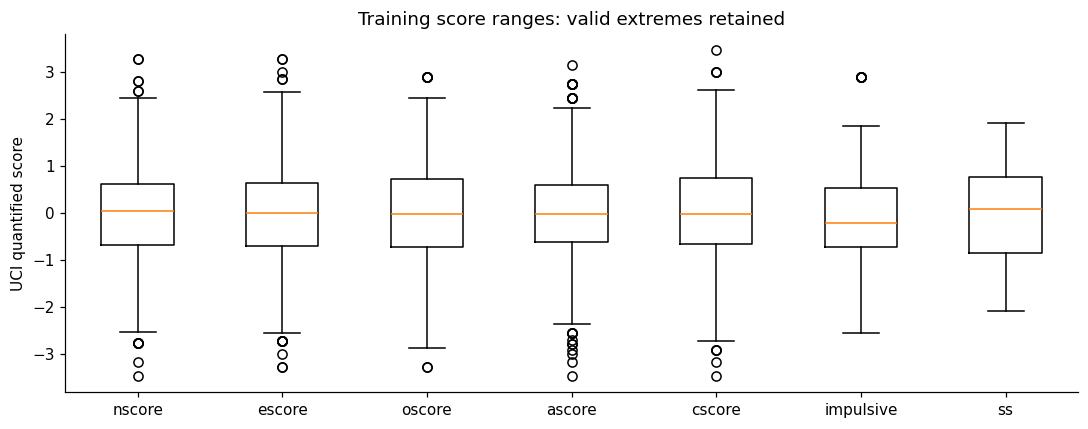

In [8]:
SCORES = ["nscore", "escore", "oscore", "ascore", "cscore", "impulsive", "ss"]
summary = train[FEATURES].describe().T
summary.to_csv(REPORTS / "training_numeric_summary.csv")
display(summary.round(3))
axes = train[SCORES].hist(bins=20, figsize=(12, 9), color="#4477aa", edgecolor="white")
fig = axes.ravel()[0].figure
fig.suptitle("Training score distributions", y=1.01)
fig.tight_layout()
fig.savefig(FIGURES / "training_score_distributions.png", bbox_inches="tight")
plt.show()
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([train[c].to_numpy() for c in SCORES], tick_labels=SCORES)
ax.set(title="Training score ranges: valid extremes retained", ylabel="UCI quantified score")
fig.tight_layout()
fig.savefig(FIGURES / "training_score_boxplots.png", bbox_inches="tight")
plt.show()

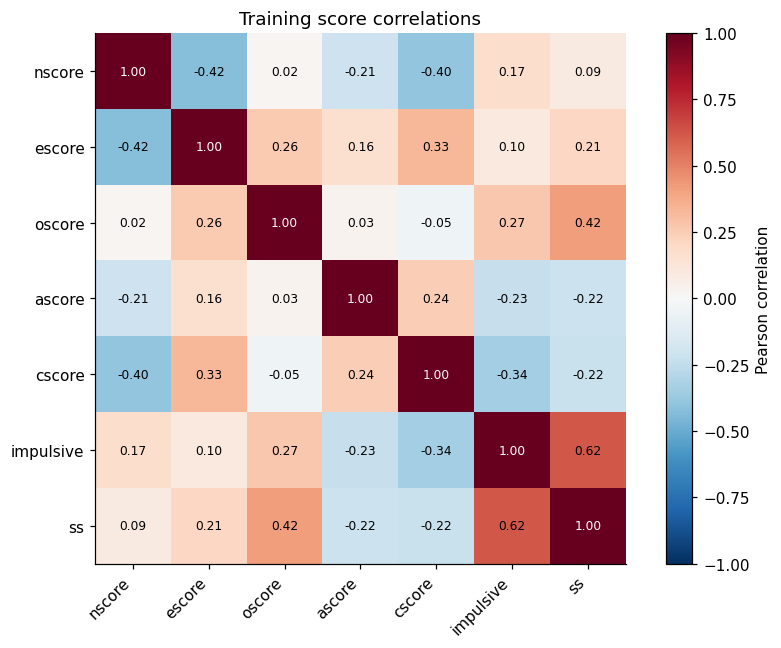

In [9]:
# Exclude nominal demographic codes: their numeric distances are not meaningful.
corr = train[SCORES].corr()
fig, ax = plt.subplots(figsize=(8, 6))
heatmap = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(SCORES)), SCORES, rotation=45, ha="right")
ax.set_yticks(range(len(SCORES)), SCORES)
for row in range(len(SCORES)):
    for col in range(len(SCORES)):
        value = corr.iloc[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > 0.65 else "black")
ax.set_title("Training score correlations")
fig.colorbar(heatmap, ax=ax, label="Pearson correlation")
fig.tight_layout()
fig.savefig(FIGURES / "training_score_correlations.png", bbox_inches="tight")
plt.show()
corr.to_csv(REPORTS / "training_score_correlations.csv")

## 6. Fit preprocessing using training data only

Decode and one-hot encode **gender, country, ethnicity**, avoiding artificial numeric distances between nominal categories. Learn categories from training only; unseen categories transform to an all-zero indicator block.

Keep quantified age and education as ordered numeric representations, plus the seven scores. Standardize these nine columns with training means/standard deviations. This retains UCI's supplied quantification; that original transformation predates our split and cannot be independently refitted from this released file.

All indicator columns are retained; later models should handle redundancy appropriately (for example with regularization). No imputation, oversampling, class weighting, or feature selection is applied. Save the transformer for reuse.

In [10]:
CATEGORICAL = ["gender", "country", "ethnicity"]
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]
def decode_nominal(frame):
    result = frame.copy()
    for column in CATEGORICAL:
        result[column] = result[column].round(5).map(MAPS[column])
    assert not result.isna().any().any()
    return result

X_train, X_test = decode_nominal(X_train_q), decode_nominal(X_test_q)
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), NUMERIC),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
], remainder="drop", verbose_feature_names_out=False)
# Fit ONLY on training; reuse this object to transform the test set.
train_array = preprocessor.fit_transform(X_train)
names = preprocessor.get_feature_names_out()
X_train_ready = pd.DataFrame(train_array, index=X_train.index, columns=names)
X_test_ready = pd.DataFrame(preprocessor.transform(X_test), index=X_test.index, columns=names)
joblib.dump(preprocessor, OUT / "preprocessor.joblib")
for name, frame in {"X_train": X_train, "X_test": X_test, "X_train_ready": X_train_ready,
                    "X_test_ready": X_test_ready, "y_train": y_train, "y_test": y_test}.items():
    # ID is an alignment index, not a feature. Reload with index_col="id".
    frame.to_csv(OUT / f"{name}.csv", index_label="id")
print("Prepared shapes:", X_train_ready.shape, X_test_ready.shape)
display(X_train_ready.head())

Prepared shapes: (1501, 25) (376, 25)


,age,education,nscore,escore,oscore,ascore,cscore,impulsive,ss,gender_Female,...,country_Republic of Ireland,country_UK,country_USA,ethnicity_Asian,ethnicity_Black,ethnicity_Mixed-Black/Asian,ethnicity_Mixed-White/Asian,ethnicity_Mixed-White/Black,ethnicity_Other,ethnicity_White
id,,,,,,,,,,,,,,,,,,,,,
158,-0.132740,-1.814861,-1.060707,1.121543,-1.823417,-0.448526,0.765905,-0.236505,0.816605,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
408,1.206901,0.470557,1.865342,-0.930486,1.673961,-0.014186,-0.384558,0.185631,0.437745,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1533,-1.130228,-0.640381,1.037274,-1.741315,0.597152,-0.151267,-2.526431,0.894804,-0.204824,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1629,-0.132740,1.209546,0.641278,0.016094,-0.007454,0.761243,0.009923,-1.434215,-0.527738,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1443,-0.132740,1.209546,1.037274,-0.930486,-0.707778,1.284480,0.944971,-1.434215,-1.592371,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


## 7. Validate and document the handoff

Check disjoint membership, target alignment, excluded response columns, finite values, and training-only scaling. Verify split reproducibility and exported-file round trips.

In [11]:
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_train.index) | set(X_test.index) == set(indexed.index)
assert X_train_ready.index.equals(y_train.index) and X_test_ready.index.equals(y_test.index)
assert X_train.columns.tolist() == FEATURES
assert not set(DRUGS + ["id", TARGET]) & set(X_train.columns)
assert X_train_ready.columns.equals(X_test_ready.columns)
assert set(y_train.unique()) == set(y_test.unique()) == {0, 1, 2}
assert np.isfinite(X_train_ready.to_numpy()).all() and np.isfinite(X_test_ready.to_numpy()).all()
scaler = preprocessor.named_transformers_["numeric"]
np.testing.assert_allclose(scaler.mean_, X_train[NUMERIC].mean().to_numpy())
np.testing.assert_allclose(X_train_ready[NUMERIC].mean(), 0, atol=1e-12)
assert int(scaler.n_samples_seen_) == len(X_train)
repeat_train, repeat_test = train_test_split(X.index, test_size=TEST_SIZE, random_state=SEED, stratify=y)
assert list(repeat_train) == list(X_train.index) and list(repeat_test) == list(X_test.index)
loaded_X = pd.read_csv(OUT / "X_train_ready.csv", index_col="id")
loaded_y = pd.read_csv(OUT / "y_train.csv", index_col="id")[TARGET]
pd.testing.assert_frame_equal(loaded_X, X_train_ready, check_exact=False)
pd.testing.assert_series_equal(loaded_y, y_train)
np.testing.assert_allclose(joblib.load(OUT / "preprocessor.joblib").transform(X_test), X_test_ready)
metadata = {"dataset_url": "https://archive.ics.uci.edu/dataset/373/drug+consumption+quantified",
    "raw_sha256": raw_hash, "target_mapping": TARGET_MAP, "class_names": CLASS_NAMES,
    "seed": SEED, "test_fraction": TEST_SIZE, "train_rows": len(y_train), "test_rows": len(y_test),
    "predictors": FEATURES, "numeric": NUMERIC, "categorical": CATEGORICAL,
    "transformed_columns": list(names), "quality": quality,
    "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                 "numpy": np.__version__, "scikit-learn": sklearn.__version__}}
(REPORTS / "preparation_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("All preparation checks passed.")

All preparation checks passed.


## 8. Findings and next steps

- 1,885 raw respondents; no missing values or exact duplicate responses.
- Excluding eight Semeron-positive responses leaves **1,877** respondents.
- Valid extreme scores are retained. Class balance and demographic representation are described using training data only.
- This is a self-reported survey with uneven representation. Small demographic groups limit group-level conclusions. Random splitting does not establish generalization to other populations.
- The target describes recency, not dependence or future consumption. Associations are not causal effects.

**Phase 2 handoff:** load the ready X/y CSVs with `index_col="id"`. No intercept column is included; a from-scratch implementation can add one. Logistic regression must support three classes, such as softmax or one-vs-rest.

For cross-validation, start from `X_train.csv` and clone/refit preprocessing inside each fold. Using the already transformed training matrix for tuning would allow validation folds to influence scaling. Keep the holdout for final evaluation. Useful metrics include macro-F1, per-class recall and a confusion matrix, alongside accuracy.

This notebook stops at Phase 1: no models are trained or evaluated.

In [12]:
report = f"""# Phase 1 results

Source: https://archive.ics.uci.edu/dataset/373/drug+consumption+quantified

- Raw respondents: {len(raw):,}; columns: {raw.shape[1]}.
- Missing values: {quality['missing_cells']}; exact duplicate responses: {quality['duplicate_responses_raw']}.
- Semeron exclusions: {quality['semeron_excluded']}; cleaned respondents: {len(clean):,}.
- Training/test rows: {len(y_train):,}/{len(y_test):,}; stratified 80/20, seed {SEED}.
- Target: 0=never (CL0), 1=former (CL1-CL2), 2=recent (CL3-CL6).
- Training class counts: {counts.to_dict()}.
- Predictors: 12 original, {X_train_ready.shape[1]} after transformation.
- Nominal demographics one-hot encoded; nine numeric attributes standardized on training only.
- No imputation, outlier deletion, resampling or predictive model fitting.
- All preparation, leakage, reproducibility and file round-trip checks passed.

Limitations: self-report, uneven survey sampling, small demographic groups and source
quantification already applied before release. These are sample descriptions, not causal effects.
See the notebook for training-only tables, charts and explanations.
"""
(REPORTS / "phase1_summary.md").write_text(report, encoding="utf-8")
print(report)

# Phase 1 results

Source: https://archive.ics.uci.edu/dataset/373/drug+consumption+quantified

- Raw respondents: 1,885; columns: 32.
- Missing values: 0; exact duplicate responses: 0.
- Semeron exclusions: 8; cleaned respondents: 1,877.
- Training/test rows: 1,501/376; stratified 80/20, seed 42.
- Target: 0=never (CL0), 1=former (CL1-CL2), 2=recent (CL3-CL6).
- Training class counts: {0: 330, 1: 378, 2: 793}.
- Predictors: 12 original, 25 after transformation.
- Nominal demographics one-hot encoded; nine numeric attributes standardized on training only.
- No imputation, outlier deletion, resampling or predictive model fitting.
- All preparation, leakage, reproducibility and file round-trip checks passed.

Limitations: self-report, uneven survey sampling, small demographic groups and source
quantification already applied before release. These are sample descriptions, not causal effects.
See the notebook for training-only tables, charts and explanations.

